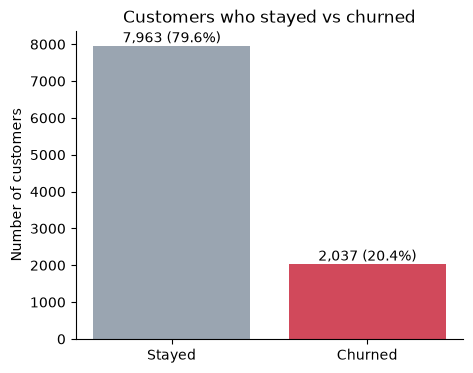

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/bank_churn_clean.csv")

counts = df["Exited"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Stayed", "Churned"], counts.values, color=["#9aa5b1", "#d1495b"])
ax.bar_label(bars, labels=[f"{c:,} ({c / len(df):.1%})" for c in counts.values])
ax.set_title("Customers who stayed vs churned")
ax.set_ylabel("Number of customers")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

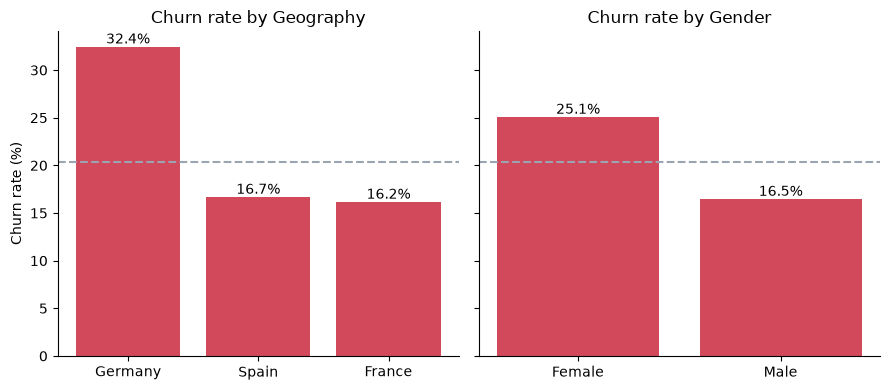

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

for ax, col in zip(axes, ["Geography", "Gender"]):
    rate = df.groupby(col)["Exited"].mean().sort_values(ascending=False) * 100
    bars = ax.bar(rate.index, rate.values, color="#d1495b")
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in rate.values])
    ax.axhline(df["Exited"].mean() * 100, color="#9aa5b1", linestyle="--")
    ax.set_title(f"Churn rate by {col}")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()